In [1]:
import pandas as pd
import numpy as np
import torch

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEMILLA = 42

np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

device = "cuda" if torch.cuda.is_available() else "cpu"

carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

auditorias = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

categorias = sorted(
    auditorias["categoria"].dropna().unique()
)

print("Dispositivo:", device)
print("Registros históricos:", len(auditorias))
print("Categorías disponibles:", len(categorias))

print("\nCategorías:")
for categoria in categorias:
    print("-", categoria)

Dispositivo: cuda
Registros históricos: 5000
Categorías disponibles: 12

Categorías:
- Condiciones locativas
- Control documental SG-SST
- Elementos de proteccion personal
- Formacion y competencias SST
- Gestion SST de contratistas
- Gestion de sustancias quimicas
- Identificacion de peligros y valoracion de riesgos
- Inspecciones y mantenimiento
- Investigacion de incidentes y accidentes
- Preparacion y respuesta a emergencias
- Seguridad de maquinas y herramientas
- Trabajo en alturas


In [2]:
INTENCIONES = [
    "conteo",
    "ranking",
    "comparacion_anual",
    "listado"
]

ENTIDADES = [
    "hallazgos",
    "auditorias"
]

ESTADOS = [
    "NINGUNO",
    "Abierto",
    "Cerrado",
    "En seguimiento"
]

CATEGORIAS = [
    "NINGUNA"
] + categorias

print("Intenciones:", len(INTENCIONES))
print("Entidades:", len(ENTIDADES))
print("Estados:", len(ESTADOS))
print("Categorías posibles:", len(CATEGORIAS))

Intenciones: 4
Entidades: 2
Estados: 4
Categorías posibles: 13


In [3]:
ejemplos = [
    # CONTEO GENERAL
    ("¿Cuántos hallazgos se registraron?",
     "conteo", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Necesito saber la cantidad total de casos.",
     "conteo", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("¿Qué volumen de observaciones tenemos?",
     "conteo", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("¿Cuántos registros existen durante 2025?",
     "conteo", "hallazgos", "NINGUNA", "NINGUNO", 2025),

    # CONTEO POR CATEGORÍA
    ("¿Cuántos problemas de protección personal hubo?",
     "conteo", "hallazgos",
     "Elementos de proteccion personal", "NINGUNO", None),

    ("¿Qué cantidad de casos relacionados con arneses tenemos?",
     "conteo", "hallazgos",
     "Trabajo en alturas", "NINGUNO", None),

    ("¿Cuántas situaciones sobre productos químicos se reportaron?",
     "conteo", "hallazgos",
     "Gestion de sustancias quimicas", "NINGUNO", None),

    ("¿Cuántos casos de capacitación fueron identificados?",
     "conteo", "hallazgos",
     "Formacion y competencias SST", "NINGUNO", None),

    # FILTROS POR ESTADO
    ("¿Cuántos hallazgos siguen abiertos?",
     "conteo", "hallazgos", "NINGUNA", "Abierto", None),

    ("Dime el número de casos que fueron cerrados.",
     "conteo", "hallazgos", "NINGUNA", "Cerrado", None),

    ("¿Cuántas observaciones permanecen en seguimiento?",
     "conteo", "hallazgos", "NINGUNA", "En seguimiento", None),

    # AUDITORÍAS
    ("¿Cuántas auditorías fueron realizadas?",
     "conteo", "auditorias", "NINGUNA", "NINGUNO", None),

    ("Necesito conocer el número de auditorías de 2024.",
     "conteo", "auditorias", "NINGUNA", "NINGUNO", 2024),

    # RANKING
    ("¿Cuáles son las categorías con más hallazgos?",
     "ranking", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("¿Qué tipos de problemas se presentan con mayor frecuencia?",
     "ranking", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Ordena los tipos de incumplimientos por cantidad.",
     "ranking", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Quiero conocer las categorías más recurrentes.",
     "ranking", "hallazgos", "NINGUNA", "NINGUNO", None),

    # COMPARACIÓN ANUAL
    ("¿En qué año se registraron más hallazgos?",
     "comparacion_anual", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Compara los registros entre diferentes años.",
     "comparacion_anual", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("¿Cómo evolucionó el número de casos anualmente?",
     "comparacion_anual", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("¿Hubo más observaciones en 2024 o en 2025?",
     "comparacion_anual", "hallazgos", "NINGUNA", "NINGUNO", None),

    # LISTADO
    ("Muéstrame los hallazgos que se registraron.",
     "listado", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Quiero revisar los detalles de los casos.",
     "listado", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Enséñame las observaciones pendientes de cierre.",
     "listado", "hallazgos", "NINGUNA", "NINGUNO", None),

    ("Necesito consultar los registros de seguridad.",
     "listado", "hallazgos", "NINGUNA", "NINGUNO", None)
]

columnas = [
    "pregunta",
    "intencion",
    "entidad",
    "categoria",
    "estado",
    "anio"
]

dataset_preguntas = pd.DataFrame(
    ejemplos,
    columns=columnas
)

print("Preguntas iniciales:", len(dataset_preguntas))

display(dataset_preguntas.head(10))

Preguntas iniciales: 25


,pregunta,intencion,entidad,categoria,estado,anio
0,¿Cuántos hallazgos se registraron?,conteo,hallazgos,NINGUNA,NINGUNO,NaN
1,Necesito saber la cantidad total de casos.,conteo,hallazgos,NINGUNA,NINGUNO,NaN
2,¿Qué volumen de observaciones tenemos?,conteo,hallazgos,NINGUNA,NINGUNO,NaN
3,¿Cuántos registros existen durante 2025?,conteo,hallazgos,NINGUNA,NINGUNO,2025.0
4,¿Cuántos problemas de protección personal hubo?,conteo,hallazgos,Elementos de proteccion personal,NINGUNO,NaN
5,¿Qué cantidad de casos relacionados con arnese...,conteo,hallazgos,Trabajo en alturas,NINGUNO,NaN
6,¿Cuántas situaciones sobre productos químicos ...,conteo,hallazgos,Gestion de sustancias quimicas,NINGUNO,NaN
7,¿Cuántos casos de capacitación fueron identifi...,conteo,hallazgos,Formacion y competencias SST,NINGUNO,NaN
8,¿Cuántos hallazgos siguen abiertos?,conteo,hallazgos,NINGUNA,Abierto,NaN
9,Dime el número de casos que fueron cerrados.,conteo,hallazgos,NINGUNA,Cerrado,NaN


In [4]:
print("Distribución por intención:")
display(
    dataset_preguntas["intencion"].value_counts()
)

print("\nDistribución por categoría:")
display(
    dataset_preguntas["categoria"].value_counts()
)

print("\nDistribución por estado:")
display(
    dataset_preguntas["estado"].value_counts()
)

print("\nValores faltantes:")
display(
    dataset_preguntas.isna().sum()
)

print("\nPreguntas repetidas:")
print(
    dataset_preguntas["pregunta"].duplicated().sum()
)

Distribución por intención:


intencion
conteo               13
ranking               4
comparacion_anual     4
listado               4
Name: count, dtype: int64


Distribución por categoría:


categoria
NINGUNA                             21
Elementos de proteccion personal     1
Trabajo en alturas                   1
Gestion de sustancias quimicas       1
Formacion y competencias SST         1
Name: count, dtype: int64


Distribución por estado:


estado
NINGUNO           22
Abierto            1
Cerrado            1
En seguimiento     1
Name: count, dtype: int64


Valores faltantes:


pregunta      0
intencion     0
entidad       0
categoria     0
estado        0
anio         23
dtype: int64


Preguntas repetidas:
0


In [5]:
# Trabajaremos sobre una copia de nuestros ejemplos
preguntas_base = dataset_preguntas.copy()

# Separar los ejemplos que requieren
# una definición más precisa
mascara_revision = preguntas_base["pregunta"].str.contains(
    r"2024 o en 2025|pendientes de cierre",
    case=False,
    regex=True
)

preguntas_revision = preguntas_base[
    mascara_revision
].copy()

preguntas_base = preguntas_base[
    ~mascara_revision
].copy()

print("Preguntas listas:", len(preguntas_base))
print("Preguntas pendientes de revisión:", len(preguntas_revision))

display(
    preguntas_revision[
        ["pregunta", "intencion", "estado", "anio"]
    ]
)

Preguntas listas: 23
Preguntas pendientes de revisión: 2


,pregunta,intencion,estado,anio
20,¿Hubo más observaciones en 2024 o en 2025?,comparacion_anual,NINGUNO,NaN
23,Enséñame las observaciones pendientes de cierre.,listado,NINGUNO,NaN


In [6]:
ejemplos_categorias = {
    "Condiciones locativas": [
        "¿Cuántos problemas se encontraron en pisos y pasillos?",
        "Muéstrame los hallazgos por desorden en las instalaciones.",
        "¿Qué cantidad de casos hubo por condiciones inseguras en las escaleras?"
    ],

    "Control documental SG-SST": [
        "¿Cuántos documentos de seguridad estaban desactualizados?",
        "Muéstrame los registros con procedimientos sin actualizar.",
        "¿Qué cantidad de observaciones hubo sobre documentos del sistema de gestión?"
    ],

    "Elementos de proteccion personal": [
        "¿Cuántos trabajadores fueron reportados sin sus elementos de protección?",
        "Muéstrame los hallazgos relacionados con el uso incorrecto de EPP.",
        "¿Cuántas observaciones se hicieron por falta de gafas y guantes?"
    ],

    "Formacion y competencias SST": [
        "¿Cuántos incumplimientos se relacionaron con falta de capacitación?",
        "Muéstrame los casos donde el personal no recibió inducción.",
        "¿Qué cantidad de hallazgos hubo por ausencia de entrenamiento?"
    ],

    "Gestion SST de contratistas": [
        "¿Cuántos problemas se detectaron en los requisitos de los contratistas?",
        "Muéstrame los hallazgos de seguridad del personal subcontratado.",
        "¿Qué cantidad de incumplimientos hubo con empresas contratistas?"
    ],

    "Gestion de sustancias quimicas": [
        "¿Cuántas irregularidades hubo en el almacenamiento de químicos?",
        "Muéstrame los hallazgos relacionados con productos químicos peligrosos.",
        "¿Cuántos casos se reportaron por sustancias sin etiquetar?"
    ],

    "Identificacion de peligros y valoracion de riesgos": [
        "¿Cuántos peligros laborales no fueron identificados?",
        "Muéstrame los hallazgos sobre evaluación de riesgos.",
        "¿Cuántos incumplimientos hubo por falta de medidas de control?"
    ],

    "Inspecciones y mantenimiento": [
        "¿Cuántas inspecciones programadas no se realizaron?",
        "Muéstrame los casos relacionados con mantenimiento preventivo.",
        "¿Qué cantidad de equipos tenían revisiones pendientes?"
    ],

    "Investigacion de incidentes y accidentes": [
        "¿Cuántos accidentes laborales quedaron sin investigar?",
        "Muéstrame los hallazgos sobre reportes de incidentes.",
        "¿Cuántas investigaciones de accidentes tuvieron incumplimientos?"
    ],

    "Preparacion y respuesta a emergencias": [
        "¿Cuántos problemas se encontraron en los planes de evacuación?",
        "Muéstrame los hallazgos relacionados con simulacros.",
        "¿Cuántos incumplimientos hubo con los equipos de emergencia?"
    ],

    "Seguridad de maquinas y herramientas": [
        "¿Cuántas máquinas tenían guardas de seguridad defectuosas?",
        "Muéstrame los hallazgos relacionados con herramientas peligrosas.",
        "¿Cuántas observaciones hubo por uso inseguro de maquinaria?"
    ],

    "Trabajo en alturas": [
        "¿Cuántos incumplimientos se encontraron en actividades elevadas?",
        "Muéstrame los problemas relacionados con arneses y líneas de vida.",
        "¿Qué cantidad de hallazgos hubo por riesgo de caídas desde altura?"
    ]
}

nuevos_ejemplos = []

for categoria, preguntas in ejemplos_categorias.items():

    for pregunta in preguntas:

        # Clasificar la intención según
        # la anotación que estamos definiendo
        intencion = (
            "listado"
            if pregunta.startswith("Muéstrame")
            else "conteo"
        )

        nuevos_ejemplos.append({
            "pregunta": pregunta,
            "intencion": intencion,
            "entidad": "hallazgos",
            "categoria": categoria,
            "estado": "NINGUNO",
            "anio": None
        })

df_nuevos = pd.DataFrame(nuevos_ejemplos)

print("Preguntas nuevas:", len(df_nuevos))
print("Categorías cubiertas:", df_nuevos["categoria"].nunique())

Preguntas nuevas: 36
Categorías cubiertas: 12


In [7]:
dataset_ampliado = pd.concat(
    [
        preguntas_base,
        df_nuevos
    ],
    ignore_index=True
)

# Evitar preguntas repetidas
dataset_ampliado = dataset_ampliado.drop_duplicates(
    subset=["pregunta"]
).reset_index(drop=True)

print("Total de preguntas:", len(dataset_ampliado))

print("\nDistribución por intención:")
display(
    dataset_ampliado["intencion"].value_counts()
)

print("\nDistribución por categoría:")
display(
    dataset_ampliado["categoria"].value_counts()
)

print("\nCategorías todavía sin ejemplos:")
sin_ejemplos = set(categorias) - set(
    dataset_ampliado["categoria"]
)

print(sin_ejemplos)

print("\nPreguntas duplicadas:")
print(
    dataset_ampliado["pregunta"].duplicated().sum()
)

Total de preguntas: 59

Distribución por intención:


intencion
conteo               37
listado              15
ranking               4
comparacion_anual     3
Name: count, dtype: int64


Distribución por categoría:


categoria
NINGUNA                                               19
Elementos de proteccion personal                       4
Trabajo en alturas                                     4
Gestion de sustancias quimicas                         4
Formacion y competencias SST                           4
Condiciones locativas                                  3
Control documental SG-SST                              3
Gestion SST de contratistas                            3
Identificacion de peligros y valoracion de riesgos     3
Inspecciones y mantenimiento                           3
Investigacion de incidentes y accidentes               3
Preparacion y respuesta a emergencias                  3
Seguridad de maquinas y herramientas                   3
Name: count, dtype: int64


Categorías todavía sin ejemplos:
set()

Preguntas duplicadas:
0


In [8]:
nuevas_preguntas = [
    # RANKING
    ("¿Cuáles son los incumplimientos más recurrentes?", "ranking"),
    ("Identifica los tipos de hallazgos que predominan.", "ranking"),
    ("¿Qué clases de problemas aparecen con mayor frecuencia?", "ranking"),
    ("Presenta las categorías ordenadas por número de casos.", "ranking"),
    ("Necesito saber qué riesgos se reportan más.", "ranking"),
    ("¿Dónde se concentra la mayor cantidad de observaciones?", "ranking"),
    ("Muéstrame los principales grupos de incumplimientos.", "ranking"),
    ("¿Qué categorías encabezan las estadísticas?", "ranking"),
    ("Organiza los tipos de hallazgos de mayor a menor frecuencia.", "ranking"),
    ("¿Cuáles son las situaciones más repetidas en las auditorías?", "ranking"),
    ("Quiero identificar las categorías predominantes.", "ranking"),
    ("¿Qué problemas de seguridad se presentan más habitualmente?", "ranking"),

    # COMPARACIÓN ANUAL
    ("¿Cómo ha variado la cantidad de hallazgos entre años?", "comparacion_anual"),
    ("¿En cuál de los años encontramos más incumplimientos?", "comparacion_anual"),
    ("Compara las cifras de los diferentes períodos anuales.", "comparacion_anual"),
    ("¿Los problemas de seguridad han aumentado con los años?", "comparacion_anual"),
    ("Quiero ver la evolución de los registros año tras año.", "comparacion_anual"),
    ("¿Qué diferencias encontramos entre los resultados anuales?", "comparacion_anual"),
    ("Analiza el comportamiento histórico de los hallazgos por año.", "comparacion_anual"),
    ("¿Ha disminuido la cantidad de casos con el paso del tiempo?", "comparacion_anual"),
    ("Muéstrame la tendencia anual de incumplimientos.", "comparacion_anual"),
    ("¿En qué período anual tuvimos el mayor número de casos?", "comparacion_anual"),
    ("Necesito comparar los resultados de las auditorías por año.", "comparacion_anual"),
    ("¿Qué año registró menos observaciones?", "comparacion_anual")
]

filas_nuevas = []

for pregunta, intencion in nuevas_preguntas:
    filas_nuevas.append({
        "pregunta": pregunta,
        "intencion": intencion,
        "entidad": "hallazgos",
        "categoria": "NINGUNA",
        "estado": "NINGUNO",
        "anio": None
    })

df_intenciones = pd.DataFrame(filas_nuevas)

print("Preguntas añadidas:", len(df_intenciones))
display(df_intenciones.head())

Preguntas añadidas: 24


,pregunta,intencion,entidad,categoria,estado,anio
0,¿Cuáles son los incumplimientos más recurrentes?,ranking,hallazgos,NINGUNA,NINGUNO,None
1,Identifica los tipos de hallazgos que predominan.,ranking,hallazgos,NINGUNA,NINGUNO,None
2,¿Qué clases de problemas aparecen con mayor fr...,ranking,hallazgos,NINGUNA,NINGUNO,None
3,Presenta las categorías ordenadas por número d...,ranking,hallazgos,NINGUNA,NINGUNO,None
4,Necesito saber qué riesgos se reportan más.,ranking,hallazgos,NINGUNA,NINGUNO,None


In [9]:
preguntas_combinadas = [
    (
        "¿Cuántos casos de protección personal siguen abiertos en 2025?",
        "conteo", "Elementos de proteccion personal", "Abierto", 2025
    ),
    (
        "Muéstrame los hallazgos de trabajo en alturas cerrados en 2024.",
        "listado", "Trabajo en alturas", "Cerrado", 2024
    ),
    (
        "¿Cuántos problemas con sustancias químicas están en seguimiento?",
        "conteo", "Gestion de sustancias quimicas", "En seguimiento", None
    ),
    (
        "Enséñame los incumplimientos de capacitación abiertos durante 2026.",
        "listado", "Formacion y competencias SST", "Abierto", 2026
    ),
    (
        "¿Qué cantidad de problemas locativos fueron cerrados en 2025?",
        "conteo", "Condiciones locativas", "Cerrado", 2025
    ),
    (
        "Necesito revisar las observaciones documentales en seguimiento.",
        "listado", "Control documental SG-SST", "En seguimiento", None
    ),
    (
        "¿Cuántos incumplimientos de contratistas están abiertos?",
        "conteo", "Gestion SST de contratistas", "Abierto", None
    ),
    (
        "Muéstrame las observaciones de maquinaria cerradas en 2026.",
        "listado", "Seguridad de maquinas y herramientas", "Cerrado", 2026
    ),
    (
        "¿Cuántos problemas de inspecciones permanecen en seguimiento?",
        "conteo", "Inspecciones y mantenimiento", "En seguimiento", None
    ),
    (
        "Enséñame los casos de investigación de accidentes abiertos.",
        "listado", "Investigacion de incidentes y accidentes", "Abierto", None
    ),
    (
        "¿Cuántos hallazgos de emergencias se cerraron durante 2024?",
        "conteo", "Preparacion y respuesta a emergencias", "Cerrado", 2024
    ),
    (
        "Muéstrame los casos de valoración de riesgos en seguimiento.",
        "listado", "Identificacion de peligros y valoracion de riesgos",
        "En seguimiento", None
    ),
    (
        "¿Cuántos hallazgos abiertos se encontraron durante 2025?",
        "conteo", "NINGUNA", "Abierto", 2025
    ),
    (
        "Quiero revisar los registros cerrados durante 2026.",
        "listado", "NINGUNA", "Cerrado", 2026
    ),
    (
        "¿Cuántas observaciones siguen en seguimiento durante 2024?",
        "conteo", "NINGUNA", "En seguimiento", 2024
    ),
    (
        "Enséñame todos los casos abiertos registrados en 2025.",
        "listado", "NINGUNA", "Abierto", 2025
    )
]

df_combinadas = pd.DataFrame(
    preguntas_combinadas,
    columns=[
        "pregunta",
        "intencion",
        "categoria",
        "estado",
        "anio"
    ]
)

df_combinadas["entidad"] = "hallazgos"

df_combinadas = df_combinadas[
    [
        "pregunta",
        "intencion",
        "entidad",
        "categoria",
        "estado",
        "anio"
    ]
]

print("Consultas combinadas:", len(df_combinadas))

display(df_combinadas)

Consultas combinadas: 16


,pregunta,intencion,entidad,categoria,estado,anio
0,¿Cuántos casos de protección personal siguen a...,conteo,hallazgos,Elementos de proteccion personal,Abierto,2025.0
1,Muéstrame los hallazgos de trabajo en alturas ...,listado,hallazgos,Trabajo en alturas,Cerrado,2024.0
2,¿Cuántos problemas con sustancias químicas est...,conteo,hallazgos,Gestion de sustancias quimicas,En seguimiento,NaN
3,Enséñame los incumplimientos de capacitación a...,listado,hallazgos,Formacion y competencias SST,Abierto,2026.0
4,¿Qué cantidad de problemas locativos fueron ce...,conteo,hallazgos,Condiciones locativas,Cerrado,2025.0
5,Necesito revisar las observaciones documentale...,listado,hallazgos,Control documental SG-SST,En seguimiento,NaN
6,¿Cuántos incumplimientos de contratistas están...,conteo,hallazgos,Gestion SST de contratistas,Abierto,NaN
7,Muéstrame las observaciones de maquinaria cerr...,listado,hallazgos,Seguridad de maquinas y herramientas,Cerrado,2026.0
8,¿Cuántos problemas de inspecciones permanecen ...,conteo,hallazgos,Inspecciones y mantenimiento,En seguimiento,NaN
9,Enséñame los casos de investigación de acciden...,listado,hallazgos,Investigacion de incidentes y accidentes,Abierto,NaN


In [10]:
dataset_entrenamiento = pd.concat(
    [
        dataset_ampliado,
        df_intenciones,
        df_combinadas
    ],
    ignore_index=True
)

dataset_entrenamiento = (
    dataset_entrenamiento
    .drop_duplicates(subset=["pregunta"])
    .reset_index(drop=True)
)

print("TOTAL DE PREGUNTAS:", len(dataset_entrenamiento))

print("\nIntenciones:")
display(
    dataset_entrenamiento["intencion"].value_counts()
)

print("\nCategorías:")
display(
    dataset_entrenamiento["categoria"].value_counts()
)

print("\nEstados:")
display(
    dataset_entrenamiento["estado"].value_counts()
)

print("\nPreguntas con año:")
print(dataset_entrenamiento["anio"].notna().sum())

print("\nDuplicados:")
print(dataset_entrenamiento["pregunta"].duplicated().sum())

# Comprobar etiquetas válidas
assert set(dataset_entrenamiento["intencion"]) <= set(INTENCIONES)
assert set(dataset_entrenamiento["categoria"]) <= set(CATEGORIAS)
assert set(dataset_entrenamiento["estado"]) <= set(ESTADOS)

print("\nValidación de etiquetas completada.")

TOTAL DE PREGUNTAS: 99

Intenciones:


intencion
conteo               45
listado              23
ranking              16
comparacion_anual    15
Name: count, dtype: int64


Categorías:


categoria
NINGUNA                                               47
Elementos de proteccion personal                       5
Trabajo en alturas                                     5
Gestion de sustancias quimicas                         5
Formacion y competencias SST                           5
Condiciones locativas                                  4
Control documental SG-SST                              4
Gestion SST de contratistas                            4
Identificacion de peligros y valoracion de riesgos     4
Inspecciones y mantenimiento                           4
Investigacion de incidentes y accidentes               4
Preparacion y respuesta a emergencias                  4
Seguridad de maquinas y herramientas                   4
Name: count, dtype: int64


Estados:


estado
NINGUNO           80
Abierto            7
Cerrado            6
En seguimiento     6
Name: count, dtype: int64


Preguntas con año:
12

Duplicados:
0

Validación de etiquetas completada.


In [11]:
# Guardar nuestro dataset de preguntas
ruta_preguntas = carpeta / "preguntas_entrenamiento_sst.csv"

dataset_entrenamiento.to_csv(
    ruta_preguntas,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset guardado correctamente")
print("Ruta:", ruta_preguntas)
print("Preguntas:", len(dataset_entrenamiento))

Dataset guardado correctamente
Ruta: ..\data\preguntas_entrenamiento_sst.csv
Preguntas: 99


In [12]:
from sklearn.model_selection import train_test_split

train_preguntas, val_preguntas = train_test_split(
    dataset_entrenamiento,
    test_size=0.20,
    random_state=42,
    stratify=dataset_entrenamiento["intencion"]
)

train_preguntas = train_preguntas.reset_index(drop=True)
val_preguntas = val_preguntas.reset_index(drop=True)

print("Entrenamiento:", len(train_preguntas))
print("Validación:", len(val_preguntas))

print("\nDistribución de entrenamiento:")
display(train_preguntas["intencion"].value_counts())

print("\nDistribución de validación:")
display(val_preguntas["intencion"].value_counts())

Entrenamiento: 79
Validación: 20

Distribución de entrenamiento:


intencion
conteo               36
listado              18
ranking              13
comparacion_anual    12
Name: count, dtype: int64


Distribución de validación:


intencion
conteo               9
listado              5
comparacion_anual    3
ranking              3
Name: count, dtype: int64

In [13]:
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"

modelo_nlp = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

# Embeddings de entrenamiento
X_train = modelo_nlp.encode(
    train_preguntas["pregunta"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    batch_size=16,
    show_progress_bar=True
)

# Embeddings de validación
X_val = modelo_nlp.encode(
    val_preguntas["pregunta"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    batch_size=16,
    show_progress_bar=True
)

print("Embeddings de entrenamiento:", X_train.shape)
print("Embeddings de validación:", X_val.shape)

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 2/2 [00:00<00:00, 48.77it/s]

Embeddings de entrenamiento: (79, 384)
Embeddings de validación: (20, 384)


In [14]:
from sklearn.preprocessing import LabelEncoder

campos = [
    "intencion",
    "categoria",
    "estado",
    "entidad"
]

encoders = {}
y_train = {}
y_val = {}

for campo in campos:

    encoder = LabelEncoder()

    # Las etiquetas posibles ya están definidas
    if campo == "intencion":
        clases = INTENCIONES
    elif campo == "categoria":
        clases = CATEGORIAS
    elif campo == "estado":
        clases = ESTADOS
    else:
        clases = ENTIDADES

    encoder.fit(clases)

    encoders[campo] = encoder

    y_train[campo] = encoder.transform(
        train_preguntas[campo]
    )

    y_val[campo] = encoder.transform(
        val_preguntas[campo]
    )

    print(
        campo,
        "- Clases:",
        len(encoder.classes_)
    )

intencion - Clases: 4
categoria - Clases: 13
estado - Clases: 4
entidad - Clases: 2


In [15]:
import torch.nn as nn

class InterpreteSST(nn.Module):

    def __init__(self, entrada, encoders):
        super().__init__()

        # Representación compartida
        self.red_compartida = nn.Sequential(
            nn.Linear(entrada, 128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # Cabezas de clasificación
        self.cabezas = nn.ModuleDict({
            campo: nn.Linear(
                128,
                len(encoder.classes_)
            )
            for campo, encoder in encoders.items()
        })

    def forward(self, x):

        representacion = self.red_compartida(x)

        return {
            campo: cabeza(representacion)
            for campo, cabeza in self.cabezas.items()
        }


interprete = InterpreteSST(
    entrada=X_train.shape[1],
    encoders=encoders
).to(device)

parametros = sum(
    p.numel()
    for p in interprete.parameters()
)

print("Intérprete creado correctamente")
print("Parámetros entrenables:", parametros)
print(interprete)

Intérprete creado correctamente
Parámetros entrenables: 52247
InterpreteSST(
  (red_compartida): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (cabezas): ModuleDict(
    (intencion): Linear(in_features=128, out_features=4, bias=True)
    (categoria): Linear(in_features=128, out_features=13, bias=True)
    (estado): Linear(in_features=128, out_features=4, bias=True)
    (entidad): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [16]:
from torch.utils.data import TensorDataset, DataLoader

# Convertir embeddings a tensores
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

# Etiquetas para cada tarea
y_train_tensores = [
    torch.tensor(y_train[campo], dtype=torch.long)
    for campo in campos
]

y_val_tensores = [
    torch.tensor(y_val[campo], dtype=torch.long)
    for campo in campos
]

dataset_train = TensorDataset(
    X_train_tensor,
    *y_train_tensores
)

dataset_val = TensorDataset(
    X_val_tensor,
    *y_val_tensores
)

loader_train = DataLoader(
    dataset_train,
    batch_size=8,
    shuffle=True
)

loader_val = DataLoader(
    dataset_val,
    batch_size=16,
    shuffle=False
)

print("Lotes de entrenamiento:", len(loader_train))
print("Lotes de validación:", len(loader_val))

Lotes de entrenamiento: 10
Lotes de validación: 2


In [17]:
# Obtener un lote
lote = next(iter(loader_train))

entradas = lote[0].to(device)

# Predicciones iniciales
interprete.eval()

with torch.no_grad():
    salidas = interprete(entradas)

print("Dimensión de entrada:", entradas.shape)

for campo, logits in salidas.items():
    print(
        campo,
        "->",
        tuple(logits.shape)
    )

Dimensión de entrada: torch.Size([8, 384])
intencion -> (8, 4)
categoria -> (8, 13)
estado -> (8, 4)
entidad -> (8, 2)


In [18]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
import copy
import numpy as np

# Función de pérdida
criterio = nn.CrossEntropyLoss()

# Optimizador
optimizador = AdamW(
    interprete.parameters(),
    lr=0.001,
    weight_decay=0.01
)

# Configuración
EPOCAS = 50
PACIENCIA = 8

# Tareas que vamos a evaluar principalmente
tareas_principales = [
    "intencion",
    "categoria",
    "estado"
]

print("Entrenamiento multitarea configurado")
print("Épocas máximas:", EPOCAS)
print("Early stopping:", PACIENCIA)
print("Dispositivo:", device)

Entrenamiento multitarea configurado
Épocas máximas: 50
Early stopping: 8
Dispositivo: cuda


In [19]:
historial = {
    "train_loss": [],
    "val_accuracy_completa": [],
    "val_f1_promedio": []
}

mejor_f1 = -1.0
mejor_epoca = 0
mejores_pesos = None
epocas_sin_mejora = 0

for epoca in range(EPOCAS):

    # ENTRENAMIENTO
    interprete.train()

    perdida_total = 0
    total = 0

    for lote in loader_train:

        entradas = lote[0].to(device)

        etiquetas = {
            campo: lote[i + 1].to(device)
            for i, campo in enumerate(campos)
        }

        optimizador.zero_grad()

        salidas = interprete(entradas)

        # No entrenamos entidad todavía,
        # porque solo hay ejemplos de hallazgos.
        perdida = sum(
            criterio(salidas[campo], etiquetas[campo])
            for campo in tareas_principales
        )

        perdida.backward()
        optimizador.step()

        perdida_total += perdida.item() * len(entradas)
        total += len(entradas)

    train_loss = perdida_total / total

    # VALIDACIÓN
    interprete.eval()

    reales = {campo: [] for campo in campos}
    predichos = {campo: [] for campo in campos}

    with torch.inference_mode():

        for lote in loader_val:

            entradas = lote[0].to(device)
            salidas = interprete(entradas)

            for i, campo in enumerate(campos):

                etiquetas = lote[i + 1]

                predicciones = torch.argmax(
                    salidas[campo], dim=1
                )

                reales[campo].extend(etiquetas.tolist())
                predichos[campo].extend(
                    predicciones.cpu().tolist()
                )

    # Métricas por tarea
    f1_tareas = {}

    for campo in tareas_principales:

        f1_tareas[campo] = f1_score(
            reales[campo],
            predichos[campo],
            average="macro",
            labels=list(range(len(encoders[campo].classes_))),
            zero_division=0
        )

    f1_promedio = np.mean(list(f1_tareas.values()))

    # Una interpretación es correcta solamente
    # si acierta las tres tareas principales.
    aciertos_completos = [
        all(
            reales[campo][i] == predichos[campo][i]
            for campo in tareas_principales
        )
        for i in range(len(reales["intencion"]))
    ]

    accuracy_completa = np.mean(aciertos_completos)

    historial["train_loss"].append(train_loss)
    historial["val_accuracy_completa"].append(
        accuracy_completa
    )
    historial["val_f1_promedio"].append(f1_promedio)

    print(
        f"Época {epoca+1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"F1 promedio: {f1_promedio:.4f} | "
        f"Exactitud completa: {accuracy_completa:.4f}"
    )

    # Guardar mejor modelo
    if f1_promedio > mejor_f1 + 1e-4:

        mejor_f1 = f1_promedio
        mejor_epoca = epoca + 1

        mejores_pesos = copy.deepcopy(
            interprete.state_dict()
        )

        epocas_sin_mejora = 0

    else:
        epocas_sin_mejora += 1

    if epocas_sin_mejora >= PACIENCIA:
        print("\nEarly stopping activado")
        break

# Restaurar mejor modelo
interprete.load_state_dict(mejores_pesos)
interprete.eval()

print("\nENTRENAMIENTO FINALIZADO")
print("Mejor época:", mejor_epoca)
print("Mejor F1 promedio:", round(mejor_f1, 4))

Época 01 | Loss: 5.3129 | F1 promedio: 0.1994 | Exactitud completa: 0.1000
Época 02 | Loss: 5.0555 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 03 | Loss: 4.6593 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 04 | Loss: 4.1604 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 05 | Loss: 3.7768 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 06 | Loss: 3.5848 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 07 | Loss: 3.4421 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 08 | Loss: 3.2843 | F1 promedio: 0.1429 | Exactitud completa: 0.1000
Época 09 | Loss: 3.1332 | F1 promedio: 0.2381 | Exactitud completa: 0.1500
Época 10 | Loss: 2.9985 | F1 promedio: 0.2381 | Exactitud completa: 0.1500
Época 11 | Loss: 2.8451 | F1 promedio: 0.2381 | Exactitud completa: 0.1500
Época 12 | Loss: 2.7271 | F1 promedio: 0.2655 | Exactitud completa: 0.2000
Época 13 | Loss: 2.5646 | F1 promedio: 0.3096 | Exactitud completa: 0.2500
Época 14 | Loss: 2.4507 |

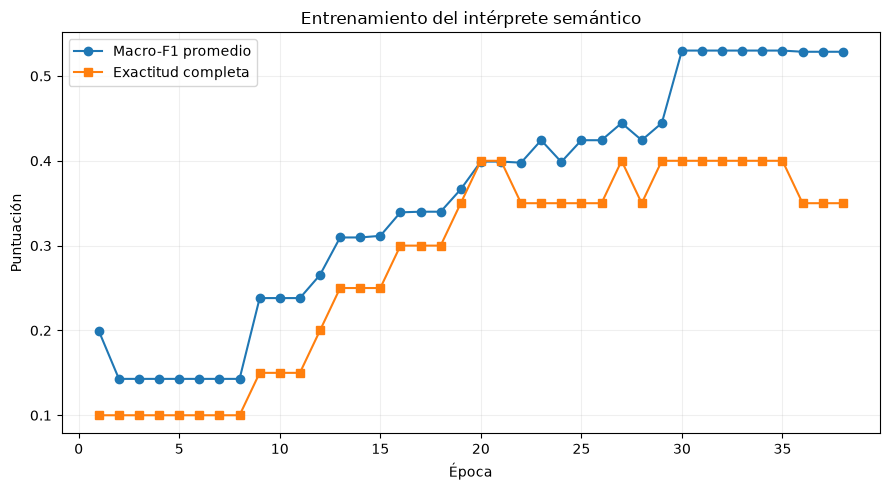

In [20]:
import matplotlib.pyplot as plt

epocas = range(
    1,
    len(historial["train_loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epocas,
    historial["val_f1_promedio"],
    marker="o",
    label="Macro-F1 promedio"
)

plt.plot(
    epocas,
    historial["val_accuracy_completa"],
    marker="s",
    label="Exactitud completa"
)

plt.xlabel("Época")
plt.ylabel("Puntuación")
plt.title("Entrenamiento del intérprete semántico")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

import pandas as pd
import torch

# Recuperamos el mejor modelo
interprete.eval()

predicciones = {
    campo: []
    for campo in tareas_principales
}

etiquetas_reales = {
    campo: []
    for campo in tareas_principales
}

with torch.inference_mode():

    for lote in loader_val:

        entradas = lote[0].to(device)

        salidas = interprete(entradas)

        for i, campo in enumerate(campos):

            if campo not in tareas_principales:
                continue

            pred = torch.argmax(
                salidas[campo],
                dim=1
            ).cpu().numpy()

            reales_lote = lote[i + 1].numpy()

            predicciones[campo].extend(pred)
            etiquetas_reales[campo].extend(reales_lote)


# Calcular las métricas por tarea
metricas = []

for campo in tareas_principales:

    accuracy = accuracy_score(
        etiquetas_reales[campo],
        predicciones[campo]
    )

    macro_f1 = f1_score(
        etiquetas_reales[campo],
        predicciones[campo],
        average="macro",
        labels=list(
            range(len(encoders[campo].classes_))
        ),
        zero_division=0
    )

    metricas.append({
        "tarea": campo,
        "accuracy": round(accuracy, 4),
        "macro_f1": round(macro_f1, 4)
    })

tabla_metricas = pd.DataFrame(metricas)

display(tabla_metricas)

,tarea,accuracy,macro_f1
0,intencion,0.90,0.8972
1,categoria,0.55,0.2140
2,estado,0.85,0.4786


In [22]:
# Crear tabla con predicciones reales
analisis = val_preguntas[
    ["pregunta", "intencion", "categoria", "estado"]
].copy()

for campo in tareas_principales:

    analisis[f"{campo}_predicho"] = (
        encoders[campo].inverse_transform(
            predicciones[campo]
        )
    )

# Comprobar si todos los campos coinciden
analisis["correcta"] = (
    (analisis["intencion"] == analisis["intencion_predicho"])
    &
    (analisis["categoria"] == analisis["categoria_predicho"])
    &
    (analisis["estado"] == analisis["estado_predicho"])
)

print("Preguntas evaluadas:", len(analisis))
print("Correctas:", analisis["correcta"].sum())
print("Incorrectas:", (~analisis["correcta"]).sum())

print("\nPREGUNTAS INTERPRETADAS INCORRECTAMENTE:")

display(
    analisis.loc[
        ~analisis["correcta"]
    ]
)

Preguntas evaluadas: 20
Correctas: 8
Incorrectas: 12

PREGUNTAS INTERPRETADAS INCORRECTAMENTE:


,pregunta,intencion,categoria,estado,intencion_predicho,categoria_predicho,estado_predicho,correcta
1,Muéstrame los casos donde el personal no recib...,listado,Formacion y competencias SST,NINGUNO,conteo,Formacion y competencias SST,NINGUNO,False
2,¿Cuántos casos de protección personal siguen a...,conteo,Elementos de proteccion personal,Abierto,conteo,NINGUNA,NINGUNO,False
3,¿Cuántos incumplimientos de contratistas están...,conteo,Gestion SST de contratistas,Abierto,conteo,Preparacion y respuesta a emergencias,NINGUNO,False
6,¿Los problemas de seguridad han aumentado con ...,comparacion_anual,NINGUNA,NINGUNO,conteo,NINGUNA,NINGUNO,False
7,Necesito consultar los registros de seguridad.,listado,NINGUNA,NINGUNO,listado,Control documental SG-SST,NINGUNO,False
8,Muéstrame los hallazgos de seguridad del perso...,listado,Gestion SST de contratistas,NINGUNO,listado,Seguridad de maquinas y herramientas,NINGUNO,False
10,Muéstrame los problemas relacionados con arnes...,listado,Trabajo en alturas,NINGUNO,listado,NINGUNA,NINGUNO,False
11,¿Cuántos problemas se detectaron en los requis...,conteo,Gestion SST de contratistas,NINGUNO,conteo,Elementos de proteccion personal,NINGUNO,False
13,¿Cuántos hallazgos abiertos se encontraron dur...,conteo,NINGUNA,Abierto,conteo,NINGUNA,NINGUNO,False
15,Muéstrame los hallazgos sobre reportes de inci...,listado,Investigacion de incidentes y accidentes,NINGUNO,listado,NINGUNA,NINGUNO,False


In [23]:
from sklearn.metrics import classification_report
import pandas as pd

print("REPORTE DETALLADO DE CATEGORÍAS\n")

print(
    classification_report(
        etiquetas_reales["categoria"],
        predicciones["categoria"],
        labels=list(
            range(len(encoders["categoria"].classes_))
        ),
        target_names=encoders["categoria"].classes_,
        zero_division=0
    )
)

# Cuántas preguntas solicitan una categoría
# específica y cuántas reconoce correctamente
categoria_real = analisis["categoria"] != "NINGUNA"

categoria_predicha = (
    analisis["categoria_predicho"] != "NINGUNA"
)

print("\nCategorías específicas:")

print(
    "Preguntas con categoría real:",
    categoria_real.sum()
)

print(
    "Categorías específicas detectadas:",
    (categoria_real & categoria_predicha).sum()
)

print(
    "Categorías específicas omitidas:",
    (categoria_real & ~categoria_predicha).sum()
)

print(
    "Filtros de categoría inventados:",
    (~categoria_real & categoria_predicha).sum()
)

REPORTE DETALLADO DE CATEGORÍAS

                                                    precision    recall  f1-score   support

                             Condiciones locativas       0.00      0.00      0.00         1
                         Control documental SG-SST       0.00      0.00      0.00         0
                  Elementos de proteccion personal       0.00      0.00      0.00         1
                      Formacion y competencias SST       1.00      1.00      1.00         1
                       Gestion SST de contratistas       0.00      0.00      0.00         3
                    Gestion de sustancias quimicas       1.00      1.00      1.00         1
Identificacion de peligros y valoracion de riesgos       0.00      0.00      0.00         0
                      Inspecciones y mantenimiento       0.00      0.00      0.00         0
          Investigacion de incidentes y accidentes       0.00      0.00      0.00         2
                                           NIN

In [24]:
print("REPORTE DETALLADO DE ESTADOS\n")

print(
    classification_report(
        etiquetas_reales["estado"],
        predicciones["estado"],
        labels=list(
            range(len(encoders["estado"].classes_))
        ),
        target_names=encoders["estado"].classes_,
        zero_division=0
    )
)

estado_real = analisis["estado"] != "NINGUNO"

estado_predicho = (
    analisis["estado_predicho"] != "NINGUNO"
)

print("\nEstados específicos:")

print(
    "Preguntas con estado real:",
    estado_real.sum()
)

print(
    "Estados específicos detectados:",
    (estado_real & estado_predicho).sum()
)

print(
    "Estados omitidos:",
    (estado_real & ~estado_predicho).sum()
)

print(
    "Filtros de estado inventados:",
    (~estado_real & estado_predicho).sum()
)

REPORTE DETALLADO DE ESTADOS

                precision    recall  f1-score   support

       Abierto       0.00      0.00      0.00         3
       Cerrado       1.00      1.00      1.00         1
En seguimiento       0.00      0.00      0.00         0
       NINGUNO       0.84      1.00      0.91        16

      accuracy                           0.85        20
     macro avg       0.46      0.50      0.48        20
  weighted avg       0.72      0.85      0.78        20


Estados específicos:
Preguntas con estado real: 4
Estados específicos detectados: 1
Estados omitidos: 3
Filtros de estado inventados: 0


In [25]:
# Distribución de etiquetas en entrenamiento
for campo in ["intencion", "categoria", "estado", "entidad"]:

    print(f"\n{'=' * 45}")
    print("CAMPO:", campo)

    tabla = train_preguntas[campo].value_counts()

    display(tabla)

    print("Clases presentes:", len(tabla))

# Cantidad de preguntas que mencionan filtros
resumen_filtros = pd.DataFrame({
    "filtro": ["categoria", "estado"],
    "con_filtro": [
        (train_preguntas["categoria"] != "NINGUNA").sum(),
        (train_preguntas["estado"] != "NINGUNO").sum()
    ],
    "sin_filtro": [
        (train_preguntas["categoria"] == "NINGUNA").sum(),
        (train_preguntas["estado"] == "NINGUNO").sum()
    ]
})

display(resumen_filtros)


CAMPO: intencion


intencion
conteo               36
listado              18
ranking              13
comparacion_anual    12
Name: count, dtype: int64

Clases presentes: 4

CAMPO: categoria


categoria
NINGUNA                                               37
Seguridad de maquinas y herramientas                   4
Preparacion y respuesta a emergencias                  4
Formacion y competencias SST                           4
Elementos de proteccion personal                       4
Control documental SG-SST                              4
Identificacion de peligros y valoracion de riesgos     4
Trabajo en alturas                                     4
Gestion de sustancias quimicas                         4
Inspecciones y mantenimiento                           4
Condiciones locativas                                  3
Investigacion de incidentes y accidentes               2
Gestion SST de contratistas                            1
Name: count, dtype: int64

Clases presentes: 13

CAMPO: estado


estado
NINGUNO           64
En seguimiento     6
Cerrado            5
Abierto            4
Name: count, dtype: int64

Clases presentes: 4

CAMPO: entidad


entidad
hallazgos     77
auditorias     2
Name: count, dtype: int64

Clases presentes: 2


,filtro,con_filtro,sin_filtro
0,categoria,42,37
1,estado,15,64


In [26]:
from pathlib import Path

# Crear carpeta de trabajo
ruta_revision = carpeta / "preguntas_revision_sst.csv"

# Crear plantilla de anotación
plantilla = pd.DataFrame(
    columns=[
        "pregunta",
        "intencion",
        "entidad",
        "categoria",
        "estado",
        "anio",
        "familia_pregunta",
        "revisado"
    ]
)

plantilla.to_csv(
    ruta_revision,
    index=False,
    encoding="utf-8-sig"
)

print("Plantilla creada:", ruta_revision)

Plantilla creada: ..\data\preguntas_revision_sst.csv


In [27]:
ejemplos_adicionales = [
    # ESTADOS
    ("Necesito consultar los casos que siguen sin cerrar.",
     "listado", "hallazgos", "NINGUNA", "Abierto"),

    ("¿Cuántas observaciones continúan abiertas?",
     "conteo", "hallazgos", "NINGUNA", "Abierto"),

    ("Quiero revisar los incumplimientos ya solucionados.",
     "listado", "hallazgos", "NINGUNA", "Cerrado"),

    ("¿Qué cantidad de registros fueron cerrados?",
     "conteo", "hallazgos", "NINGUNA", "Cerrado"),

    ("Enséñame los casos que todavía están siendo supervisados.",
     "listado", "hallazgos", "NINGUNA", "En seguimiento"),

    ("¿Cuántos hallazgos permanecen en seguimiento?",
     "conteo", "hallazgos", "NINGUNA", "En seguimiento"),

    # ENTIDAD AUDITORÍAS
    ("¿Cuántas auditorías fueron realizadas durante 2025?",
     "conteo", "auditorias", "NINGUNA", "NINGUNO"),

    ("Necesito conocer el total de auditorías efectuadas.",
     "conteo", "auditorias", "NINGUNA", "NINGUNO"),

    ("¿Cuántas evaluaciones de auditoría se registraron?",
     "conteo", "auditorias", "NINGUNA", "NINGUNO"),

    ("Muéstrame las auditorías realizadas.",
     "listado", "auditorias", "NINGUNA", "NINGUNO"),

    # CATEGORÍAS MENOS REPRESENTADAS
    ("¿Qué cantidad de incumplimientos presentaron los subcontratistas?",
     "conteo", "hallazgos",
     "Gestion SST de contratistas", "NINGUNO"),

    ("Necesito revisar los requisitos de seguridad incumplidos por terceros.",
     "listado", "hallazgos",
     "Gestion SST de contratistas", "NINGUNO"),

    ("¿Cuántos eventos laborales quedaron sin una investigación adecuada?",
     "conteo", "hallazgos",
     "Investigacion de incidentes y accidentes", "NINGUNO"),

    ("Muéstrame los registros relacionados con investigaciones de accidentes.",
     "listado", "hallazgos",
     "Investigacion de incidentes y accidentes", "NINGUNO"),

    # COMBINACIONES
    ("¿Qué cantidad de incumplimientos de contratistas siguen abiertos?",
     "conteo", "hallazgos",
     "Gestion SST de contratistas", "Abierto"),

    ("Enséñame los casos de equipos de protección que fueron cerrados.",
     "listado", "hallazgos",
     "Elementos de proteccion personal", "Cerrado"),

    ("¿Cuántos problemas de maquinaria permanecen en seguimiento?",
     "conteo", "hallazgos",
     "Seguridad de maquinas y herramientas", "En seguimiento"),

    ("Quiero consultar los hallazgos abiertos relacionados con emergencias.",
     "listado", "hallazgos",
     "Preparacion y respuesta a emergencias", "Abierto")
]

df_adicionales = pd.DataFrame(
    ejemplos_adicionales,
    columns=[
        "pregunta",
        "intencion",
        "entidad",
        "categoria",
        "estado"
    ]
)

df_adicionales["anio"] = None
df_adicionales["familia_pregunta"] = [
    f"adicional_{i:02d}"
    for i in range(len(df_adicionales))
]
df_adicionales["revisado"] = False

print("Preguntas adicionales:", len(df_adicionales))
display(df_adicionales)

Preguntas adicionales: 18


,pregunta,intencion,entidad,categoria,estado,anio,familia_pregunta,revisado
0,Necesito consultar los casos que siguen sin ce...,listado,hallazgos,NINGUNA,Abierto,None,adicional_00,False
1,¿Cuántas observaciones continúan abiertas?,conteo,hallazgos,NINGUNA,Abierto,None,adicional_01,False
2,Quiero revisar los incumplimientos ya solucion...,listado,hallazgos,NINGUNA,Cerrado,None,adicional_02,False
3,¿Qué cantidad de registros fueron cerrados?,conteo,hallazgos,NINGUNA,Cerrado,None,adicional_03,False
4,Enséñame los casos que todavía están siendo su...,listado,hallazgos,NINGUNA,En seguimiento,None,adicional_04,False
5,¿Cuántos hallazgos permanecen en seguimiento?,conteo,hallazgos,NINGUNA,En seguimiento,None,adicional_05,False
6,¿Cuántas auditorías fueron realizadas durante ...,conteo,auditorias,NINGUNA,NINGUNO,None,adicional_06,False
7,Necesito conocer el total de auditorías efectu...,conteo,auditorias,NINGUNA,NINGUNO,None,adicional_07,False
8,¿Cuántas evaluaciones de auditoría se registra...,conteo,auditorias,NINGUNA,NINGUNO,None,adicional_08,False
9,Muéstrame las auditorías realizadas.,listado,auditorias,NINGUNA,NINGUNO,None,adicional_09,False


In [28]:
# Verificar que todas las etiquetas existan
assert set(df_adicionales["intencion"]) <= set(INTENCIONES)
assert set(df_adicionales["categoria"]) <= set(CATEGORIAS)
assert set(df_adicionales["estado"]) <= set(ESTADOS)
assert set(df_adicionales["entidad"]) <= set(ENTIDADES)

# Guardar propuestas de anotación
df_adicionales.to_csv(
    ruta_revision,
    index=False,
    encoding="utf-8-sig"
)

print("Ejemplos guardados para revisión.")
print("Archivo:", ruta_revision)

print("\nDistribución de los nuevos estados:")
display(df_adicionales["estado"].value_counts())

print("\nDistribución de las nuevas entidades:")
display(df_adicionales["entidad"].value_counts())

Ejemplos guardados para revisión.
Archivo: ..\data\preguntas_revision_sst.csv

Distribución de los nuevos estados:


estado
NINGUNO           8
Abierto           4
Cerrado           3
En seguimiento    3
Name: count, dtype: int64


Distribución de las nuevas entidades:


entidad
hallazgos     14
auditorias     4
Name: count, dtype: int64

In [29]:
# Copia de los ejemplos adicionales
df_revision = df_adicionales.copy()

# Marcar los ejemplos no ambiguos
df_revision["revisado"] = True

# Mantener pendientes los tres casos detectados
df_revision.loc[
    [0, 2, 4],
    "revisado"
] = False

# Seleccionar ejemplos para el siguiente entrenamiento
nuevos_aprobados = df_revision[
    df_revision["revisado"]
].copy()

print("Ejemplos seleccionados:", len(nuevos_aprobados))
print("Pendientes:", (~df_revision["revisado"]).sum())

display(
    nuevos_aprobados[
        ["pregunta", "intencion", "entidad", "categoria", "estado"]
    ]
)

Ejemplos seleccionados: 15
Pendientes: 3


,pregunta,intencion,entidad,categoria,estado
1,¿Cuántas observaciones continúan abiertas?,conteo,hallazgos,NINGUNA,Abierto
3,¿Qué cantidad de registros fueron cerrados?,conteo,hallazgos,NINGUNA,Cerrado
5,¿Cuántos hallazgos permanecen en seguimiento?,conteo,hallazgos,NINGUNA,En seguimiento
6,¿Cuántas auditorías fueron realizadas durante ...,conteo,auditorias,NINGUNA,NINGUNO
7,Necesito conocer el total de auditorías efectu...,conteo,auditorias,NINGUNA,NINGUNO
8,¿Cuántas evaluaciones de auditoría se registra...,conteo,auditorias,NINGUNA,NINGUNO
9,Muéstrame las auditorías realizadas.,listado,auditorias,NINGUNA,NINGUNO
10,¿Qué cantidad de incumplimientos presentaron l...,conteo,hallazgos,Gestion SST de contratistas,NINGUNO
11,Necesito revisar los requisitos de seguridad i...,listado,hallazgos,Gestion SST de contratistas,NINGUNO
12,¿Cuántos eventos laborales quedaron sin una in...,conteo,hallazgos,Investigacion de incidentes y accidentes,NINGUNO


In [30]:
# Mantener el conjunto de validación original
val_preguntas_v2 = val_preguntas.copy()

# Añadir los ejemplos nuevos solamente a entrenamiento
train_preguntas_v2 = pd.concat(
    [
        train_preguntas,
        nuevos_aprobados[
            train_preguntas.columns.intersection(
                nuevos_aprobados.columns
            )
        ]
    ],
    ignore_index=True
)

train_preguntas_v2 = (
    train_preguntas_v2
    .drop_duplicates(subset=["pregunta"])
    .reset_index(drop=True)
)

# Comprobar que no haya preguntas idénticas
# entre entrenamiento y validación
compartidas = set(
    train_preguntas_v2["pregunta"]
) & set(
    val_preguntas_v2["pregunta"]
)

print("Entrenamiento anterior:", len(train_preguntas))
print("Entrenamiento V2:", len(train_preguntas_v2))
print("Validación:", len(val_preguntas_v2))
print("Preguntas compartidas:", len(compartidas))

assert len(compartidas) == 0

Entrenamiento anterior: 79
Entrenamiento V2: 94
Validación: 20
Preguntas compartidas: 0


In [31]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import torch

# Generar embeddings de la V2
X_train_v2 = modelo_nlp.encode(
    train_preguntas_v2["pregunta"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    batch_size=16,
    show_progress_bar=True
)

X_val_v2 = modelo_nlp.encode(
    val_preguntas_v2["pregunta"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    batch_size=16,
    show_progress_bar=True
)

# Codificadores para valores específicos
encoder_categoria_v2 = LabelEncoder()
encoder_categoria_v2.fit(
    [c for c in CATEGORIAS if c != "NINGUNA"]
)

encoder_estado_v2 = LabelEncoder()
encoder_estado_v2.fit(
    [e for e in ESTADOS if e != "NINGUNO"]
)

def preparar_etiquetas_v2(datos):

    # Presencia de filtros
    hay_categoria = (
        datos["categoria"] != "NINGUNA"
    ).astype(int).to_numpy()

    hay_estado = (
        datos["estado"] != "NINGUNO"
    ).astype(int).to_numpy()

    # Los valores específicos solo se entrenarán
    # cuando el filtro esté presente.
    categorias = datos["categoria"].where(
        datos["categoria"] != "NINGUNA",
        encoder_categoria_v2.classes_[0]
    )

    estados = datos["estado"].where(
        datos["estado"] != "NINGUNO",
        encoder_estado_v2.classes_[0]
    )

    return {
        "intencion": encoders["intencion"].transform(
            datos["intencion"]
        ),
        "entidad": encoders["entidad"].transform(
            datos["entidad"]
        ),
        "hay_categoria": hay_categoria,
        "categoria": encoder_categoria_v2.transform(
            categorias
        ),
        "hay_estado": hay_estado,
        "estado": encoder_estado_v2.transform(
            estados
        )
    }


y_train_v2 = preparar_etiquetas_v2(
    train_preguntas_v2
)

y_val_v2 = preparar_etiquetas_v2(
    val_preguntas_v2
)

print("Embeddings train:", X_train_v2.shape)
print("Embeddings val:", X_val_v2.shape)

for campo, valores in y_train_v2.items():
    print(campo, ":", valores.shape)

Batches: 100%|██████████| 2/2 [00:00<00:00, 68.95it/s]

Embeddings train: (94, 384)
Embeddings val: (20, 384)
intencion : (94,)
entidad : (94,)
hay_categoria : (94,)
categoria : (94,)
hay_estado : (94,)
estado : (94,)


In [32]:
import torch.nn as nn

class InterpreteSST_V2(nn.Module):

    def __init__(self, dimension=384):
        super().__init__()

        # Representación compartida
        self.compartida = nn.Sequential(
            nn.Linear(dimension, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        # Cabezas de predicción
        self.cabezas = nn.ModuleDict({

            "intencion": nn.Linear(
                64, len(encoders["intencion"].classes_)
            ),

            "entidad": nn.Linear(
                64, len(encoders["entidad"].classes_)
            ),

            "hay_categoria": nn.Linear(64, 2),

            "categoria": nn.Linear(
                64, len(encoder_categoria_v2.classes_)
            ),

            "hay_estado": nn.Linear(64, 2),

            "estado": nn.Linear(
                64, len(encoder_estado_v2.classes_)
            )
        })

    def forward(self, x):

        representacion = self.compartida(x)

        return {
            nombre: cabeza(representacion)
            for nombre, cabeza in self.cabezas.items()
        }


# Crear una red nueva, sin reutilizar pesos de V1
torch.manual_seed(42)

interprete_v2 = InterpreteSST_V2(
    dimension=X_train_v2.shape[1]
).to(device)

parametros = sum(
    p.numel()
    for p in interprete_v2.parameters()
)

print("Intérprete V2 creado correctamente.")
print("Parámetros entrenables:", parametros)
print(interprete_v2)

Intérprete V2 creado correctamente.
Parámetros entrenables: 59161
InterpreteSST_V2(
  (compartida): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  )
  (cabezas): ModuleDict(
    (intencion): Linear(in_features=64, out_features=4, bias=True)
    (entidad): Linear(in_features=64, out_features=2, bias=True)
    (hay_categoria): Linear(in_features=64, out_features=2, bias=True)
    (categoria): Linear(in_features=64, out_features=12, bias=True)
    (hay_estado): Linear(in_features=64, out_features=2, bias=True)
    (estado): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [33]:
from torch.utils.data import TensorDataset, DataLoader

campos_v2 = [
    "intencion",
    "entidad",
    "hay_categoria",
    "categoria",
    "hay_estado",
    "estado"
]

def crear_loader(X, etiquetas, batch_size, shuffle):

    entradas = torch.tensor(
        X, dtype=torch.float32
    )

    salidas = [
        torch.tensor(
            etiquetas[campo],
            dtype=torch.long
        )
        for campo in campos_v2
    ]

    dataset = TensorDataset(
        entradas, *salidas
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


loader_train_v2 = crear_loader(
    X_train_v2,
    y_train_v2,
    batch_size=8,
    shuffle=True
)

loader_val_v2 = crear_loader(
    X_val_v2,
    y_val_v2,
    batch_size=16,
    shuffle=False
)

# Probar un lote
lote = next(iter(loader_train_v2))

interprete_v2.eval()

with torch.no_grad():
    salidas = interprete_v2(
        lote[0].to(device)
    )

print("Entrada:", tuple(lote[0].shape))

for campo, logits in salidas.items():
    print(campo, ":", tuple(logits.shape))

Entrada: (8, 384)
intencion : (8, 4)
entidad : (8, 2)
hay_categoria : (8, 2)
categoria : (8, 12)
hay_estado : (8, 2)
estado : (8, 3)


In [34]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import copy

criterio = nn.CrossEntropyLoss()

optimizador_v2 = AdamW(
    interprete_v2.parameters(),
    lr=0.001,
    weight_decay=0.01
)

EPOCAS_V2 = 60
PACIENCIA_V2 = 10

def calcular_perdida_v2(salidas, etiquetas):

    # Tareas generales
    loss_intencion = criterio(
        salidas["intencion"],
        etiquetas["intencion"]
    )

    loss_entidad = criterio(
        salidas["entidad"],
        etiquetas["entidad"]
    )

    # Detectar presencia de filtros
    loss_hay_categoria = criterio(
        salidas["hay_categoria"],
        etiquetas["hay_categoria"]
    )

    loss_hay_estado = criterio(
        salidas["hay_estado"],
        etiquetas["hay_estado"]
    )

    # Categoría: solo donde existe el filtro
    mascara_categoria = etiquetas["hay_categoria"] == 1

    if mascara_categoria.any():
        loss_categoria = criterio(
            salidas["categoria"][mascara_categoria],
            etiquetas["categoria"][mascara_categoria]
        )
    else:
        loss_categoria = salidas["categoria"].sum() * 0

    # Estado: solo donde existe el filtro
    mascara_estado = etiquetas["hay_estado"] == 1

    if mascara_estado.any():
        loss_estado = criterio(
            salidas["estado"][mascara_estado],
            etiquetas["estado"][mascara_estado]
        )
    else:
        loss_estado = salidas["estado"].sum() * 0

    # Pérdida multitarea
    loss_total = (
        loss_intencion
        + loss_entidad
        + loss_hay_categoria
        + loss_categoria
        + loss_hay_estado
        + loss_estado
    )

    return loss_total


print("Entrenamiento V2 configurado.")
print("Épocas máximas:", EPOCAS_V2)
print("Early stopping:", PACIENCIA_V2)

Entrenamiento V2 configurado.
Épocas máximas: 60
Early stopping: 10


In [35]:
historial_v2 = {
    "train_loss": [],
    "exactitud_completa": [],
    "f1_intencion": [],
    "accuracy_categoria": [],
    "accuracy_estado": []
}

mejor_score_v2 = -1
mejor_epoca_v2 = 0
mejores_pesos_v2 = None
sin_mejora_v2 = 0

for epoca in range(EPOCAS_V2):

    # ENTRENAMIENTO
    interprete_v2.train()
    perdida_total = 0
    registros = 0

    for lote in loader_train_v2:

        entradas = lote[0].to(device)

        etiquetas = {
            campo: lote[i + 1].to(device)
            for i, campo in enumerate(campos_v2)
        }

        optimizador_v2.zero_grad()

        salidas = interprete_v2(entradas)

        perdida = calcular_perdida_v2(
            salidas,
            etiquetas
        )

        perdida.backward()

        torch.nn.utils.clip_grad_norm_(
            interprete_v2.parameters(),
            max_norm=1.0
        )

        optimizador_v2.step()

        perdida_total += perdida.item() * len(entradas)
        registros += len(entradas)

    train_loss = perdida_total / registros

    # VALIDACIÓN
    interprete_v2.eval()

    reales_v2 = {campo: [] for campo in campos_v2}
    predichos_v2 = {campo: [] for campo in campos_v2}

    with torch.inference_mode():

        for lote in loader_val_v2:

            entradas = lote[0].to(device)
            salidas = interprete_v2(entradas)

            for i, campo in enumerate(campos_v2):

                pred = torch.argmax(
                    salidas[campo],
                    dim=1
                )

                predichos_v2[campo].extend(
                    pred.cpu().tolist()
                )

                reales_v2[campo].extend(
                    lote[i + 1].tolist()
                )

    # Métricas de intención
    f1_intencion = f1_score(
        reales_v2["intencion"],
        predichos_v2["intencion"],
        average="macro",
        zero_division=0
    )

    # Reconstruir filtros predichos
    # Si no existe filtro, no se utiliza su valor
    categorias_finales = []
    estados_finales = []

    for i in range(len(reales_v2["intencion"])):

        if predichos_v2["hay_categoria"][i] == 1:
            categorias_finales.append(
                predichos_v2["categoria"][i]
            )
        else:
            categorias_finales.append(-1)

        if predichos_v2["hay_estado"][i] == 1:
            estados_finales.append(
                predichos_v2["estado"][i]
            )
        else:
            estados_finales.append(-1)

    categorias_reales_finales = [
        reales_v2["categoria"][i]
        if reales_v2["hay_categoria"][i] == 1
        else -1
        for i in range(len(categorias_finales))
    ]

    estados_reales_finales = [
        reales_v2["estado"][i]
        if reales_v2["hay_estado"][i] == 1
        else -1
        for i in range(len(estados_finales))
    ]

    accuracy_categoria = accuracy_score(
        categorias_reales_finales,
        categorias_finales
    )

    accuracy_estado = accuracy_score(
        estados_reales_finales,
        estados_finales
    )

    # Exactitud de interpretación completa:
    # intención + entidad + categoría + estado
    aciertos = []

    for i in range(len(reales_v2["intencion"])):

        correcto = (
            reales_v2["intencion"][i]
            == predichos_v2["intencion"][i]

            and reales_v2["entidad"][i]
            == predichos_v2["entidad"][i]

            and categorias_reales_finales[i]
            == categorias_finales[i]

            and estados_reales_finales[i]
            == estados_finales[i]
        )

        aciertos.append(correcto)

    exactitud_completa = np.mean(aciertos)

    # Priorizar interpretación completa y usar
    # Macro-F1 de intención como desempate
    score = exactitud_completa + 0.01 * f1_intencion

    historial_v2["train_loss"].append(train_loss)
    historial_v2["exactitud_completa"].append(
        exactitud_completa
    )
    historial_v2["f1_intencion"].append(f1_intencion)
    historial_v2["accuracy_categoria"].append(
        accuracy_categoria
    )
    historial_v2["accuracy_estado"].append(
        accuracy_estado
    )

    print(
        f"Época {epoca+1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"F1 intención: {f1_intencion:.4f} | "
        f"Cat: {accuracy_categoria:.4f} | "
        f"Estado: {accuracy_estado:.4f} | "
        f"Completa: {exactitud_completa:.4f}"
    )

    if score > mejor_score_v2 + 1e-4:

        mejor_score_v2 = score
        mejor_epoca_v2 = epoca + 1

        mejores_pesos_v2 = copy.deepcopy(
            interprete_v2.state_dict()
        )

        sin_mejora_v2 = 0

    else:
        sin_mejora_v2 += 1

    if sin_mejora_v2 >= PACIENCIA_V2:
        print("\nEarly stopping activado.")
        break

# Recuperar el mejor modelo
interprete_v2.load_state_dict(mejores_pesos_v2)
interprete_v2.eval()

print("\nENTRENAMIENTO V2 FINALIZADO")
print("Mejor época:", mejor_epoca_v2)
print("Mejor exactitud completa:",
      round(max(historial_v2["exactitud_completa"]), 4))

Época 01 | Loss: 6.7578 | F1 intención: 0.1552 | Cat: 0.0000 | Estado: 0.8000 | Completa: 0.0000
Época 02 | Loss: 6.4904 | F1 intención: 0.1552 | Cat: 0.0000 | Estado: 0.8000 | Completa: 0.0000
Época 03 | Loss: 6.3616 | F1 intención: 0.1552 | Cat: 0.0000 | Estado: 0.8000 | Completa: 0.0000
Época 04 | Loss: 5.9523 | F1 intención: 0.1552 | Cat: 0.0000 | Estado: 0.8000 | Completa: 0.0000
Época 05 | Loss: 5.8828 | F1 intención: 0.1552 | Cat: 0.1500 | Estado: 0.8000 | Completa: 0.0000
Época 06 | Loss: 5.6219 | F1 intención: 0.1552 | Cat: 0.2500 | Estado: 0.8000 | Completa: 0.0000
Época 07 | Loss: 5.3299 | F1 intención: 0.1552 | Cat: 0.4000 | Estado: 0.8000 | Completa: 0.1000
Época 08 | Loss: 5.2330 | F1 intención: 0.1607 | Cat: 0.4000 | Estado: 0.8000 | Completa: 0.1000
Época 09 | Loss: 5.0080 | F1 intención: 0.2564 | Cat: 0.4000 | Estado: 0.8000 | Completa: 0.1500
Época 10 | Loss: 4.8881 | F1 intención: 0.4137 | Cat: 0.3500 | Estado: 0.8000 | Completa: 0.1500
Época 11 | Loss: 4.6852 | F1 i

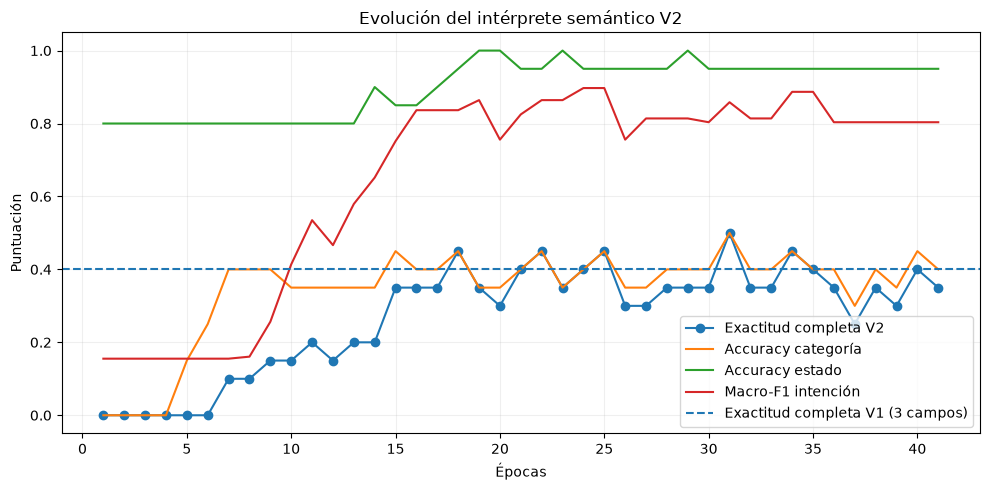

In [36]:
import matplotlib.pyplot as plt

epocas = range(
    1,
    len(historial_v2["train_loss"]) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epocas,
    historial_v2["exactitud_completa"],
    marker="o",
    label="Exactitud completa V2"
)

plt.plot(
    epocas,
    historial_v2["accuracy_categoria"],
    label="Accuracy categoría"
)

plt.plot(
    epocas,
    historial_v2["accuracy_estado"],
    label="Accuracy estado"
)

plt.plot(
    epocas,
    historial_v2["f1_intencion"],
    label="Macro-F1 intención"
)

plt.axhline(
    0.40,
    linestyle="--",
    label="Exactitud completa V1 (3 campos)"
)

plt.xlabel("Épocas")
plt.ylabel("Puntuación")
plt.title("Evolución del intérprete semántico V2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [37]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pandas as pd
import torch

interprete_v2.eval()

reales_eval = {campo: [] for campo in campos_v2}
pred_eval = {campo: [] for campo in campos_v2}

with torch.inference_mode():

    for lote in loader_val_v2:

        entradas = lote[0].to(device)
        salidas = interprete_v2(entradas)

        for i, campo in enumerate(campos_v2):

            reales_eval[campo].extend(
                lote[i + 1].tolist()
            )

            pred_eval[campo].extend(
                salidas[campo].argmax(dim=1).cpu().tolist()
            )

for filtro, valor in [
    ("hay_categoria", "categoria"),
    ("hay_estado", "estado")
]:

    presencia_real = np.array(reales_eval[filtro])
    presencia_predicha = np.array(pred_eval[filtro])

    valor_real = np.array(reales_eval[valor])
    valor_predicho = np.array(pred_eval[valor])

    print("\n", "=" * 50)
    print("FILTRO:", valor.upper())

    print("\nDetección de presencia:")

    print(classification_report(
        presencia_real,
        presencia_predicha,
        labels=[0, 1],
        target_names=["Sin filtro", "Con filtro"],
        zero_division=0
    ))

    # Evaluar el valor específico cuando realmente existe
    mascara = presencia_real == 1

    if mascara.sum() > 0:

        identificacion_correcta = (
            (presencia_predicha[mascara] == 1)
            &
            (valor_predicho[mascara] == valor_real[mascara])
        )

        print(
            "Filtros presentes identificados correctamente:",
            int(identificacion_correcta.sum()),
            "de",
            int(mascara.sum())
        )

        print(
            "Tasa de identificación:",
            f"{identificacion_correcta.mean():.2%}"
        )


FILTRO: CATEGORIA

Detección de presencia:
              precision    recall  f1-score   support

  Sin filtro       1.00      0.70      0.82        10
  Con filtro       0.77      1.00      0.87        10

    accuracy                           0.85        20
   macro avg       0.88      0.85      0.85        20
weighted avg       0.88      0.85      0.85        20

Filtros presentes identificados correctamente: 3 de 10
Tasa de identificación: 30.00%

FILTRO: ESTADO

Detección de presencia:
              precision    recall  f1-score   support

  Sin filtro       0.94      1.00      0.97        16
  Con filtro       1.00      0.75      0.86         4

    accuracy                           0.95        20
   macro avg       0.97      0.88      0.91        20
weighted avg       0.95      0.95      0.95        20

Filtros presentes identificados correctamente: 3 de 4
Tasa de identificación: 75.00%


In [38]:
analisis_v2 = val_preguntas_v2[
    ["pregunta", "intencion", "entidad", "categoria", "estado"]
].copy().reset_index(drop=True)

# Interpretaciones de intención y entidad
for campo in ["intencion", "entidad"]:

    analisis_v2[f"{campo}_predicho"] = (
        encoders[campo].inverse_transform(
            pred_eval[campo]
        )
    )

# Categoría final
categorias_predichas = []

for hay, indice in zip(
    pred_eval["hay_categoria"],
    pred_eval["categoria"]
):

    categoria = (
        encoder_categoria_v2.inverse_transform([indice])[0]
        if hay == 1
        else "NINGUNA"
    )

    categorias_predichas.append(categoria)

analisis_v2["categoria_predicha"] = categorias_predichas

# Estado final
estados_predichos = []

for hay, indice in zip(
    pred_eval["hay_estado"],
    pred_eval["estado"]
):

    estado = (
        encoder_estado_v2.inverse_transform([indice])[0]
        if hay == 1
        else "NINGUNO"
    )

    estados_predichos.append(estado)

analisis_v2["estado_predicho"] = estados_predichos

# Comparación completa
analisis_v2["correcta"] = (
    (analisis_v2["intencion"] == analisis_v2["intencion_predicho"])
    &
    (analisis_v2["entidad"] == analisis_v2["entidad_predicho"])
    &
    (analisis_v2["categoria"] == analisis_v2["categoria_predicha"])
    &
    (analisis_v2["estado"] == analisis_v2["estado_predicho"])
)

print("Correctas:", analisis_v2["correcta"].sum())
print("Incorrectas:", (~analisis_v2["correcta"]).sum())

display(
    analisis_v2.loc[
        ~analisis_v2["correcta"]
    ]
)

Correctas: 10
Incorrectas: 10


,pregunta,intencion,entidad,categoria,estado,intencion_predicho,entidad_predicho,categoria_predicha,estado_predicho,correcta
1,Muéstrame los casos donde el personal no recib...,listado,hallazgos,Formacion y competencias SST,NINGUNO,listado,hallazgos,Elementos de proteccion personal,NINGUNO,False
2,¿Cuántos casos de protección personal siguen a...,conteo,hallazgos,Elementos de proteccion personal,Abierto,conteo,hallazgos,Trabajo en alturas,NINGUNO,False
3,¿Cuántos incumplimientos de contratistas están...,conteo,hallazgos,Gestion SST de contratistas,Abierto,conteo,hallazgos,Formacion y competencias SST,Abierto,False
6,¿Los problemas de seguridad han aumentado con ...,comparacion_anual,hallazgos,NINGUNA,NINGUNO,listado,hallazgos,Gestion de sustancias quimicas,NINGUNO,False
7,Necesito consultar los registros de seguridad.,listado,hallazgos,NINGUNA,NINGUNO,listado,hallazgos,Control documental SG-SST,NINGUNO,False
8,Muéstrame los hallazgos de seguridad del perso...,listado,hallazgos,Gestion SST de contratistas,NINGUNO,listado,hallazgos,Seguridad de maquinas y herramientas,NINGUNO,False
12,¿Qué problemas de seguridad se presentan más h...,ranking,hallazgos,NINGUNA,NINGUNO,listado,hallazgos,Gestion de sustancias quimicas,NINGUNO,False
16,¿Cuántas irregularidades hubo en el almacenami...,conteo,hallazgos,Gestion de sustancias quimicas,NINGUNO,conteo,hallazgos,Inspecciones y mantenimiento,NINGUNO,False
18,¿Qué cantidad de problemas locativos fueron ce...,conteo,hallazgos,Condiciones locativas,Cerrado,conteo,hallazgos,Trabajo en alturas,Cerrado,False
19,¿Cuántos accidentes laborales quedaron sin inv...,conteo,hallazgos,Investigacion de incidentes y accidentes,NINGUNO,conteo,hallazgos,Elementos de proteccion personal,NINGUNO,False


In [39]:
from pathlib import Path
import json
import torch

ruta_modelo_v2 = Path("models/interprete_sst_v2")
ruta_modelo_v2.mkdir(parents=True, exist_ok=True)

# Guardar pesos del mejor modelo recuperado
torch.save(
    interprete_v2.state_dict(),
    ruta_modelo_v2 / "modelo.pth"
)

# Guardar la configuración necesaria para reconstruirlo
configuracion_v2 = {
    "modelo_embeddings": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    "dimension_embeddings": int(X_train_v2.shape[1]),
    "intenciones": encoders["intencion"].classes_.tolist(),
    "entidades": encoders["entidad"].classes_.tolist(),
    "categorias": encoder_categoria_v2.classes_.tolist(),
    "estados": encoder_estado_v2.classes_.tolist(),
    "mejor_epoca": int(mejor_epoca_v2),
    "exactitud_validacion": 0.50
}

with open(
    ruta_modelo_v2 / "configuracion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion_v2,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Modelo V2 guardado correctamente.")
print("Ubicación:", ruta_modelo_v2.resolve())

Modelo V2 guardado correctamente.
Ubicación: D:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\notebooks\models\interprete_sst_v2


In [40]:
import torch.nn.functional as F

def interpretar_pregunta_v2(pregunta):

    interprete_v2.eval()

    # Representación semántica de la pregunta
    embedding = modelo_nlp.encode(
        [pregunta],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    entrada = torch.tensor(
        embedding,
        dtype=torch.float32
    ).to(device)

    with torch.inference_mode():
        salidas = interprete_v2(entrada)

    # Probabilidades y predicciones
    indices = {}
    confianzas = {}

    for campo, logits in salidas.items():

        probabilidades = F.softmax(
            logits, dim=1
        )[0]

        indice = int(
            torch.argmax(probabilidades).item()
        )

        indices[campo] = indice

        confianzas[campo] = float(
            probabilidades[indice].item()
        )

    # Interpretación de intención y entidad
    intencion = encoders["intencion"].inverse_transform(
        [indices["intencion"]]
    )[0]

    entidad = encoders["entidad"].inverse_transform(
        [indices["entidad"]]
    )[0]

    # Reconstrucción de categoría
    categoria = "NINGUNA"

    if indices["hay_categoria"] == 1:
        categoria = encoder_categoria_v2.inverse_transform(
            [indices["categoria"]]
        )[0]

    # Reconstrucción de estado
    estado = "NINGUNO"

    if indices["hay_estado"] == 1:
        estado = encoder_estado_v2.inverse_transform(
            [indices["estado"]]
        )[0]

    return {
        "pregunta": pregunta,
        "intencion": intencion,
        "entidad": entidad,
        "categoria": categoria,
        "estado": estado,
        "confianzas": confianzas
    }

In [41]:
preguntas_prueba = [
    "¿Cuántos problemas relacionados con arneses se registraron?",
    "Muéstrame los hallazgos que siguen abiertos.",
    "¿Qué incumplimientos presentaron los contratistas?",
    "¿Cuántas auditorías se realizaron en 2025?",
    "¿Cuáles son los problemas más frecuentes?",
    "¿Cuántos registros sobre extintores fueron cerrados?"
]

resultados_prueba = []

for pregunta in preguntas_prueba:

    resultado = interpretar_pregunta_v2(pregunta)

    resultados_prueba.append({
        "pregunta": resultado["pregunta"],
        "intencion": resultado["intencion"],
        "entidad": resultado["entidad"],
        "categoria": resultado["categoria"],
        "estado": resultado["estado"]
    })

display(pd.DataFrame(resultados_prueba))

,pregunta,intencion,entidad,categoria,estado
0,¿Cuántos problemas relacionados con arneses se...,conteo,hallazgos,Trabajo en alturas,NINGUNO
1,Muéstrame los hallazgos que siguen abiertos.,listado,hallazgos,NINGUNA,Abierto
2,¿Qué incumplimientos presentaron los contratis...,conteo,hallazgos,Seguridad de maquinas y herramientas,NINGUNO
3,¿Cuántas auditorías se realizaron en 2025?,conteo,auditorias,NINGUNA,NINGUNO
4,¿Cuáles son los problemas más frecuentes?,ranking,hallazgos,NINGUNA,NINGUNO
5,¿Cuántos registros sobre extintores fueron cer...,conteo,hallazgos,Trabajo en alturas,Cerrado
